# 실적발표 DiD 공통 파이프라인 (보험 · 바이오 · IT)

세 산업을 **같은 코드, 같은 정의**로 분석한다. 산업별로 다른 것은 기업 목록(`config/did/universe.csv`)과 보정 파일(`config/did/*.csv`)뿐이다.
설계 근거는 `plans/2026-11-12-did-pipeline-unification.md`, 결정 이력은 `memory/pipeline-unification-decisions.md`.

| 단계 | 내용 | 코드 |
|---|---|---|
| 1 | 데이터: yfinance 실적(2020-01~)·주가(2019-12~2026-10) + SEC로 확인한 보정 | `src/did_us/data.py` |
| 2 | 이벤트 테이블: 반응일 · SUE · 회사 기준 점수(직전 8분기) · 3그룹 · 과거 상회 기록 · 점검 플래그 | `src/did_us/events.py` |
| 3 | 메인 분석: 발표 여부 스택 DiD · 연속처치 · 3그룹 · 과거 기록 | `src/did_us/estimate.py` |
| 4 | 강건성 · 대조군 부족 점검 · 코로나 점검 · 플라시보 | `src/did_us/run.py` |
| 5 | 저장: `output/<산업>/`, `output/combined/` | `src/did_us/run.py` |

> Colab에서 돌릴 때: 저장소를 클론한 뒤 `pip install yfinance pyfixest` 후 첫 셀의 `ROOT`를 저장소 경로로 바꾼다.

## 0. 설정
기본값은 통일안의 결정값이다. 바꾸고 싶은 값만 `Params(...)`에 넣는다. 예: `Params(streak_hi=6)`

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src.did_us.settings import Params, INDUSTRIES
from src.did_us.run import prepare, run_industry, combine
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

P = Params()          # 예: Params(streak_hi=6, streak_lo=4)
REFRESH = False       # True면 yfinance에서 다시 받는다 (data/raw/us/ 캐시를 덮어씀)
P

Params(price_start='2019-12-01', price_end='2026-10-31', earn_start='2020-01-01', event_start='2022-01-01', event_end='2026-09-30', covid_end='2022-01-01', nocovid_hist_start='2021-01-01', win=10, ctrl_h=10, min_ctrl=1, ctrl_pool='industry', hist_q=8, hist_min=4, sd_floor_pct=10.0, score_clip=5.0, z_cut=0.5, streak_hi=7, streak_lo=4, vol_base=(60, 21), ref_bin=(-10, -6), shock=3.0, placebo_shift=30, placebo_grid=(25, 27, 29, 31, 33, 35, 37))

## 1. 데이터 · 이벤트 테이블
세 산업을 같이 읽는다 (대조군 풀을 세 산업으로 넓히는 강건성 때문).

In [2]:
ctx = prepare(P, refresh=REFRESH)
ev = ctx["ev"]
print("SEC 보도자료로 보정한 EPS:", (ev.eps_source != "yfinance").sum(), "건 / 반응일 보정:", ev.t0_override.notna().sum(), "건")
m = ev[ev.period == "main"]
m.groupby("industry").agg(
    분석이벤트=("eid", "size"), 점수있음=("z_past", lambda s: s.notna().sum()), 교란제외=("excluded", "sum"),
    커짐=("group", lambda s: (s == "up").sum()), 예상=("group", lambda s: (s == "expected").sum()), 작아짐=("group", lambda s: (s == "down").sum()),
    예상상회비율=("beat", "mean"), 연속상회=("streak_group", lambda s: (s == "streak").sum()), 가끔상회=("streak_group", lambda s: (s == "occasional").sum()),
    첫미스=("first_miss", "sum"), EPS의심=("flag_eps", "sum"), 날짜의심=("flag_date", "sum"), 급변일=("flag_mkt_shock", "sum"), 시각혼재=("flag_mixed_timing", "sum"),
).round(2)

SEC 보도자료로 보정한 EPS: 25 건 / 반응일 보정: 8 건


,분석이벤트,점수있음,교란제외,커짐,예상,작아짐,예상상회비율,연속상회,가끔상회,첫미스,EPS의심,날짜의심,급변일,시각혼재
industry,,,,,,,,,,,,,,
bio,323,323,4,78,132,113,0.89,240,10,23,0,22,46,0
insurance,437,437,0,119,173,145,0.75,200,73,38,16,24,65,0
it,569,569,0,142,227,200,0.90,468,32,34,0,35,89,19


### 점검 메모
- **연속 상회 기준**(직전 8분기 중 7회 이상 = 연속, 4회 이하 = 가끔)은 회의 확정 전 임시값이다. 세 산업 모두 상회율이 높아 '가끔 상회'가 적다 → 아래 4-4는 '연속 상회 vs 나머지'와 '상회율 연속 변수' 두 가지로 본다.
- 플래그는 출력만 하고 메인에서 빼지 않는다. 제외 버전은 강건성에 있다.

## 2. 산업별 실행
산업마다 메인 분석 → 강건성 → 플라시보 → 저장까지 한 번에 돈다 (산업당 1분 안팎).

In [3]:
results = {}
for ind in INDUSTRIES:
    results[ind] = run_industry(ctx, ind)
    print(ind, "완료")

insurance 완료


bio 완료


it 완료


## 3. 산업 비교 (대표 숫자)
- **발표 여부**: 반응일(k=0) |AR|·비정상 거래량의 처치−대조 차이 (스택 DiD)
- **연속처치**: 회사 기준 점수 1당 CAR[0,+1] (발표 이벤트만, FE = 이벤트 + 하위그룹×k + 분기×k)
- **3그룹**: 커짐·작아짐 vs 예상의 CAR[0,+1] 차이
- **과거 기록**: 연속 상회 회사에서 점수 기울기가 얼마나 다른가 (음수 = 늘 넘기던 회사는 같은 서프라이즈에 덜 반응)

In [4]:
ts = combine(results)
tab = ts.pivot_table(index=["analysis", "metric"], columns="industry", values="coef", sort=False)[list(INDUSTRIES)]
ci = ts.assign(ci=ts.ci_low.round(2).astype(str) + " ~ " + ts.ci_high.round(2).astype(str)).pivot_table(index=["analysis", "metric"], columns="industry", values="ci", aggfunc="first", sort=False)[list(INDUSTRIES)]
display(tab.round(2)); display(ci)

industry                                           insurance     bio      it
analysis metric                                                             
발표 여부    반응일 |AR| 차이 (%p)                               3.74    2.86    5.45
         반응일 비정상 log 거래량 차이                             1.12    0.86    1.14
         반응일 거래량 (배)                                    3.06    2.37    3.14
연속처치     점수 1당 CAR[0,+1] (%p)                           1.97    1.14    2.16
3그룹      커짐 vs 예상 CAR[0,+1] (%p)                        2.67    1.86    4.14
         작아짐 vs 예상 CAR[0,+1] (%p)                      -3.23   -1.86   -2.35
과거 기록    연속 상회 회사의 점수 기울기 차이 CAR[0,+1] (%p)            -0.35   -0.45   -0.94
         상회율 +1(0→100%)당 점수 기울기 변화 CAR[0,+1] (%p)      -0.38   -2.22   -1.91
표본       분석 이벤트 수                                     437.00  319.00  569.00
         대조군 확보율 (%)                                   61.10   98.43  100.00
         이벤트당 평균 대조군 수                                  2.25    3.02   15.76

industry                                               insurance           bio             it
analysis metric                                                                              
발표 여부    반응일 |AR| 차이 (%p)                            2.99 ~ 4.49   2.49 ~ 3.23      4.6 ~ 6.3
         반응일 비정상 log 거래량 차이                          0.95 ~ 1.29    0.8 ~ 0.93    1.05 ~ 1.24
         반응일 거래량 (배)                                 2.59 ~ 3.62   2.22 ~ 2.54    2.86 ~ 3.45
연속처치     점수 1당 CAR[0,+1] (%p)                        1.32 ~ 2.63    0.28 ~ 2.0    1.29 ~ 3.03
3그룹      커짐 vs 예상 CAR[0,+1] (%p)                     1.21 ~ 4.13  -0.53 ~ 4.24    2.21 ~ 6.06
         작아짐 vs 예상 CAR[0,+1] (%p)                  -4.45 ~ -2.01  -3.78 ~ 0.06  -4.51 ~ -0.19
과거 기록    연속 상회 회사의 점수 기울기 차이 CAR[0,+1] (%p)           -1.5 ~ 0.8  -1.96 ~ 1.07    -4.09 ~ 2.2
         상회율 +1(0→100%)당 점수 기울기 변화 CAR[0,+1] (%p)   -2.59 ~ 1.84  -8.97 ~ 4.53   -8.66 ~ 4.84
표본       분석 이벤트 수                                      nan ~ nan     nan ~ nan      nan ~ nan
         대조군 확보율 (%)                                   nan ~ nan     nan ~ nan      nan ~ nan
         이벤트당 평균 대조군 수                                 nan ~ nan     nan ~ nan      nan ~ nan

## 4. 이벤트스터디 그림

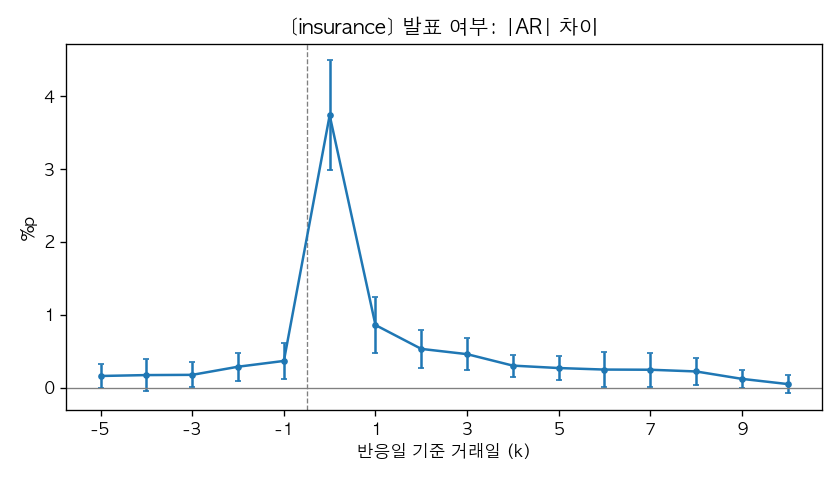

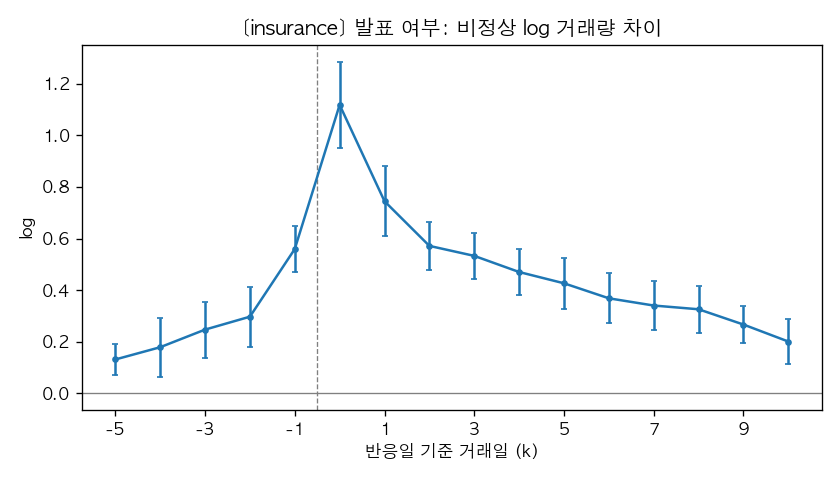

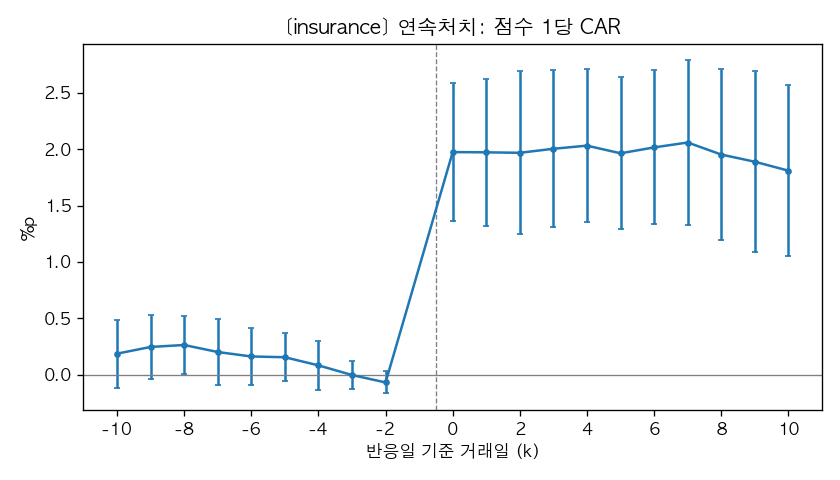

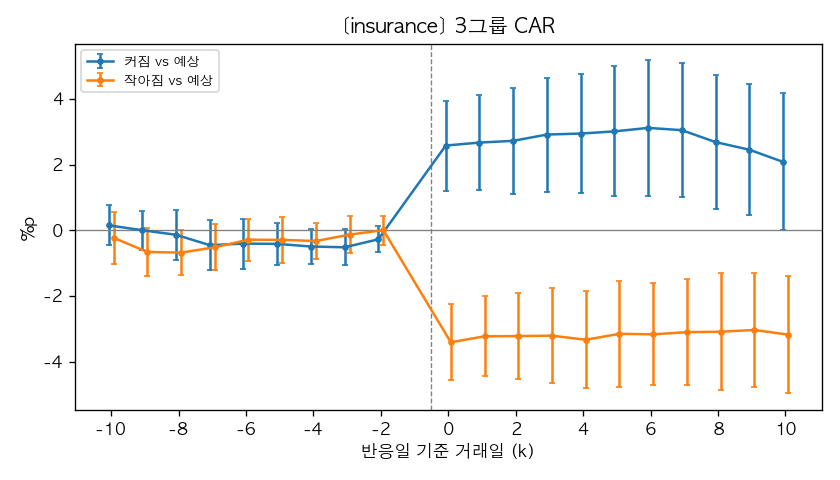

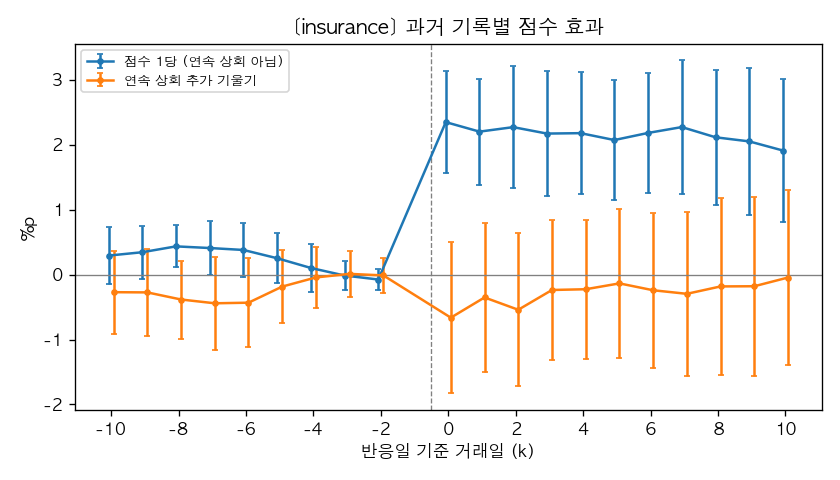

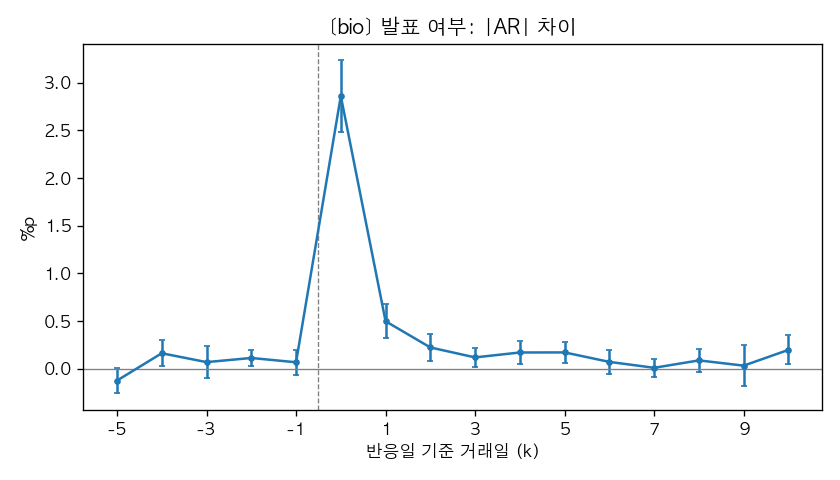

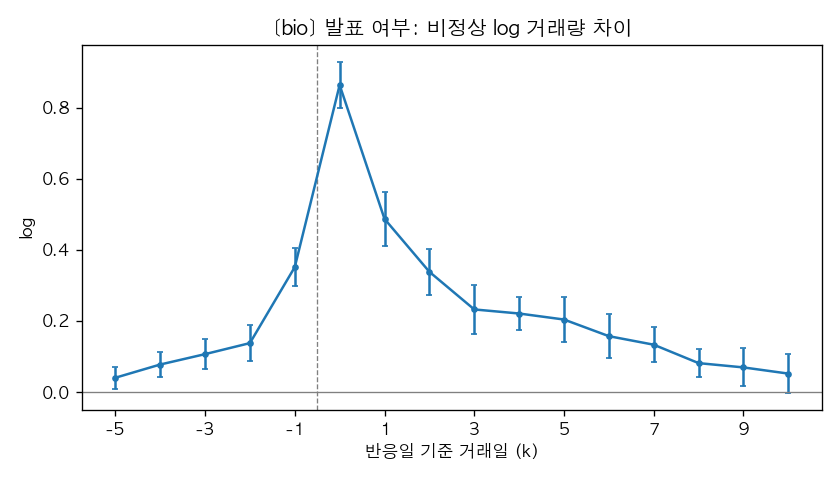

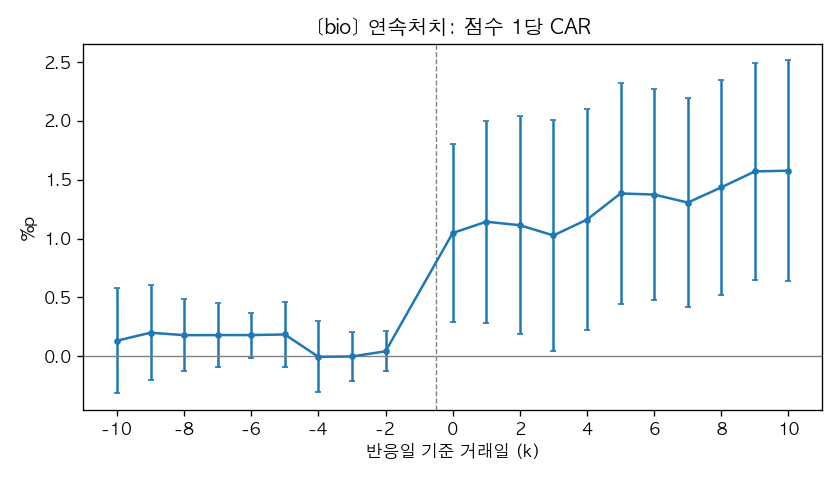

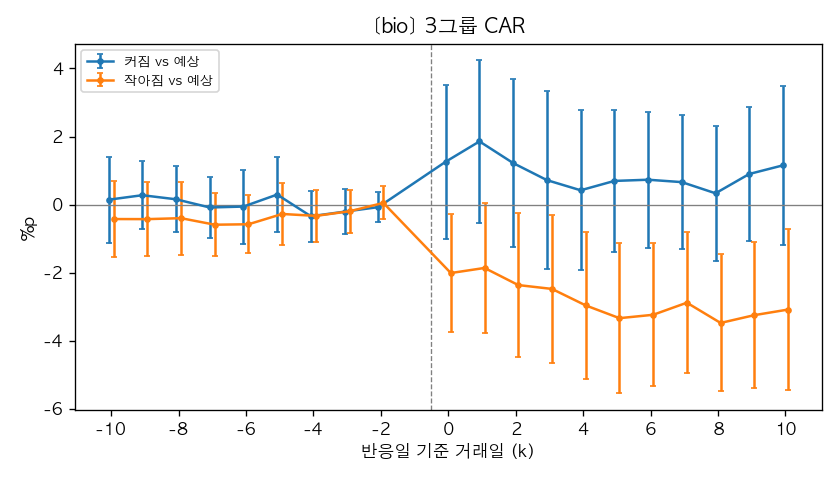

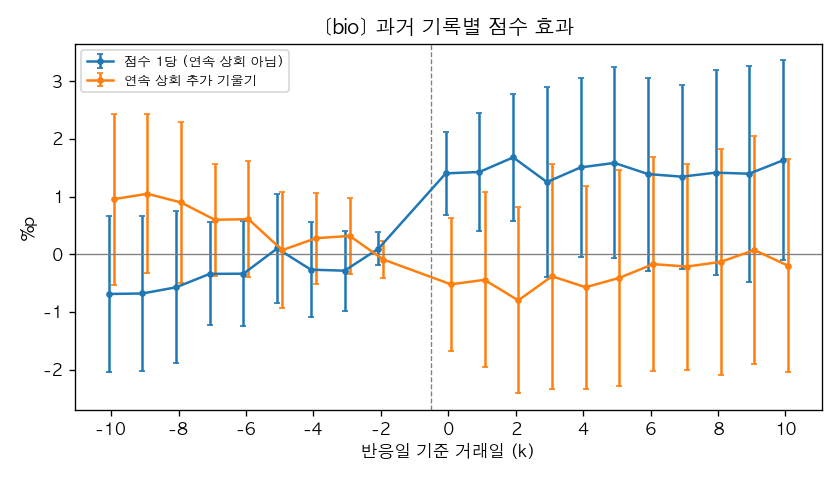

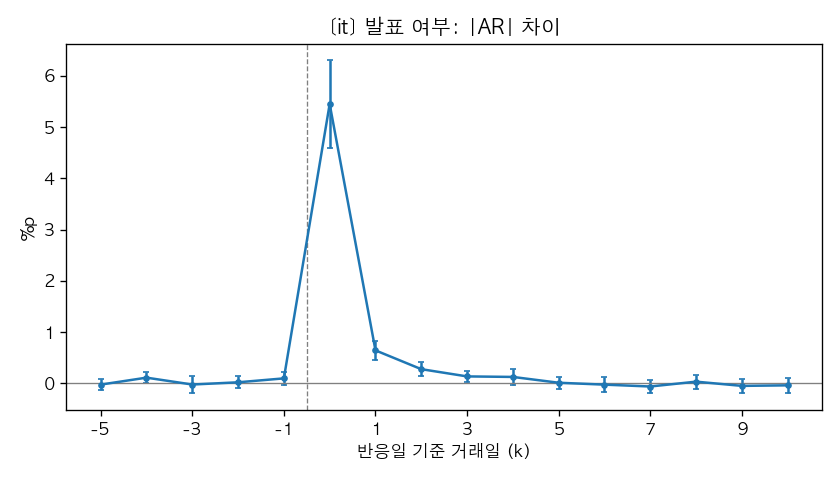

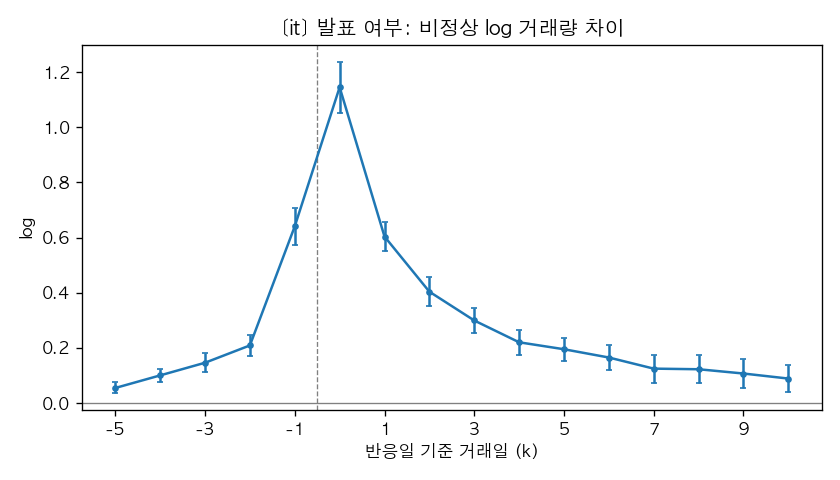

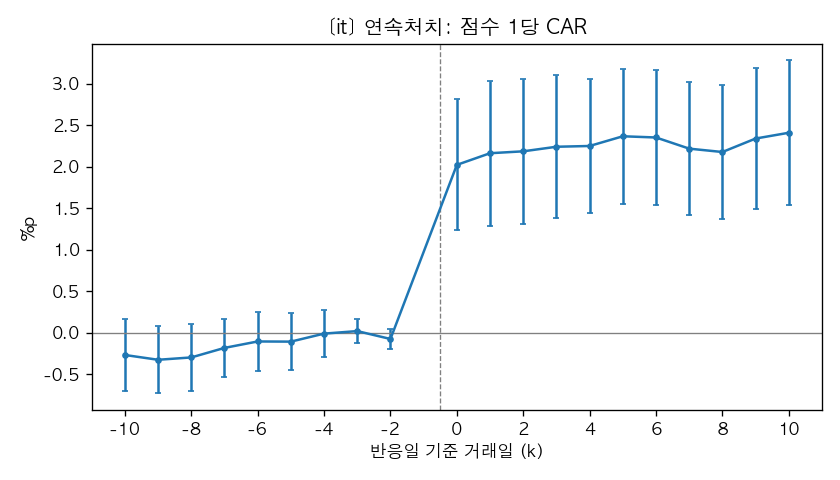

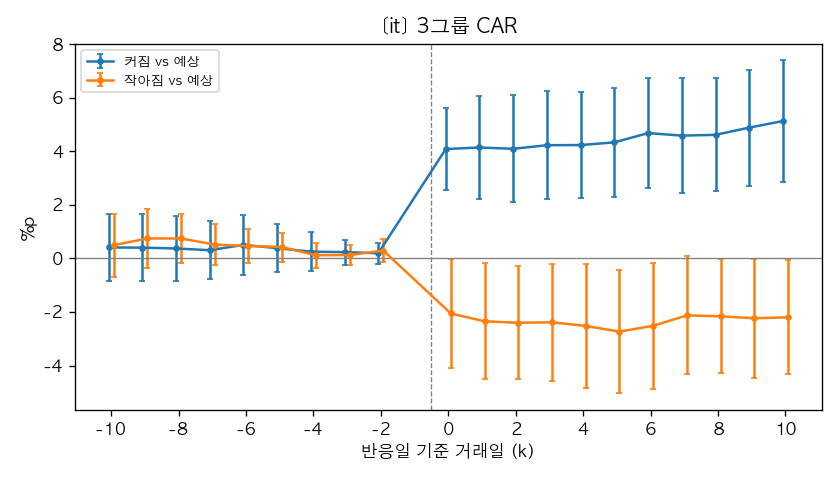

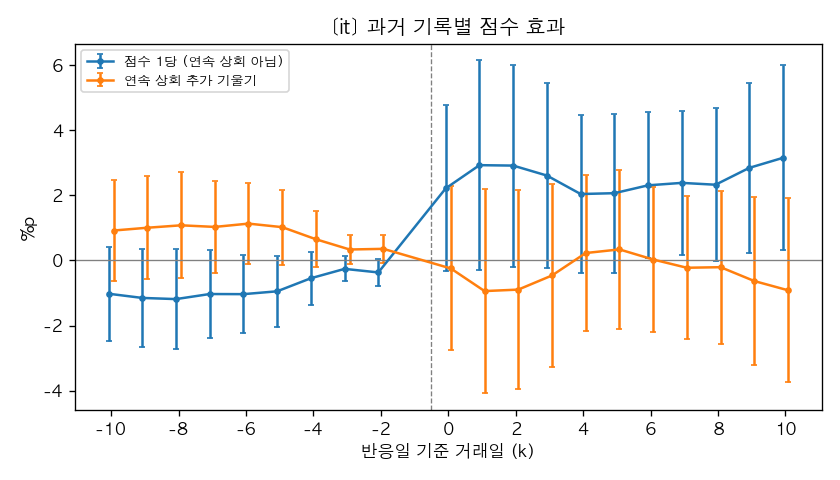

In [5]:
for ind in INDUSTRIES:
    for f in ("did_absar", "did_abvol", "cont_car", "group3_car", "streak_car"):
        display(Image(filename=str(ROOT / "output" / ind / "figures" / f"{f}.png"), width=520))

## 5. 과거 기록 (핵심 질문)
같은 서프라이즈라도 회사의 과거 기록에 따라 반응이 다른가. 아래 표는 연속상회/가끔상회 × 이번 상회/미달별 평균 CAR[0,+1](%p).

In [6]:
for ind in INDUSTRIES:
    print(f"[{ind}]"); display(results[ind]["streak_cells"].round(2))
    s = results[ind]["streak"]; display(s[s.k.isin([0, 1, 5])].round(2))

[insurance]


,streak_group,beat,count,mean,std
0,mid,beat,123,1.62,5.29
1,mid,miss,41,-3.25,6.95
2,occasional,beat,44,1.05,5.81
3,occasional,miss,29,-4.19,7.75
4,streak,beat,162,0.82,6.42
5,streak,miss,38,-2.71,5.59


,coef,se,t,p,ci_low,ci_high,var,k,n_events
9,2.35,0.38,6.23,0.00,1.57,3.13,z_past,0,437
10,2.20,0.39,5.60,0.00,1.39,3.02,z_past,1,437
14,2.07,0.45,4.64,0.00,1.15,3.00,z_past,5,437
29,-0.66,0.56,-1.18,0.25,-1.83,0.50,zS,0,437
30,-0.35,0.56,-0.63,0.53,-1.50,0.80,zS,1,437
34,-0.14,0.56,-0.24,0.81,-1.29,1.02,zS,5,437
49,1.29,0.62,2.09,0.05,0.01,2.57,S,0,437
50,1.14,0.67,1.72,0.10,-0.23,2.52,S,1,437
54,0.74,0.58,1.27,0.22,-0.47,1.95,S,5,437


[bio]


,streak_group,beat,count,mean,std
0,mid,beat,63,2.04,5.75
1,mid,miss,7,-1.73,6.71
2,occasional,beat,6,2.87,7.19
3,occasional,miss,4,-0.42,2.79
4,streak,beat,216,0.62,5.62
5,streak,miss,23,-3.10,4.65


,coef,se,t,p,ci_low,ci_high,var,k,n_events
9,1.40,0.34,4.14,0.00,0.68,2.12,z_past,0,319
10,1.43,0.49,2.94,0.01,0.40,2.45,z_past,1,319
14,1.58,0.78,2.03,0.06,-0.07,3.24,z_past,5,319
29,-0.52,0.54,-0.96,0.35,-1.68,0.63,zS,0,319
30,-0.45,0.72,-0.62,0.54,-1.96,1.07,zS,1,319
34,-0.41,0.88,-0.46,0.65,-2.28,1.46,zS,5,319
49,-0.93,0.58,-1.62,0.13,-2.16,0.29,S,0,319
50,-1.06,0.67,-1.59,0.13,-2.47,0.35,S,1,319
54,-1.83,0.76,-2.40,0.03,-3.46,-0.21,S,5,319


[it]


,streak_group,beat,count,mean,std
0,mid,beat,59,1.64,9.76
1,mid,miss,10,0.09,12.59
2,occasional,beat,19,8.03,12.49
3,occasional,miss,13,-5.16,15.14
4,streak,beat,434,0.37,8.87
5,streak,miss,34,-1.18,9.19


,coef,se,t,p,ci_low,ci_high,var,k,n_events
9,2.22,1.25,1.78,0.09,-0.34,4.77,z_past,0,569
10,2.93,1.58,1.86,0.07,-0.30,6.15,z_past,1,569
14,2.07,1.19,1.73,0.09,-0.37,4.51,z_past,5,569
29,-0.25,1.23,-0.20,0.84,-2.77,2.28,zS,0,569
30,-0.94,1.54,-0.61,0.55,-4.09,2.20,zS,1,569
34,0.34,1.19,0.29,0.78,-2.10,2.77,zS,5,569
49,-0.95,0.67,-1.42,0.17,-2.31,0.42,S,0,569
50,-1.23,0.63,-1.93,0.06,-2.52,0.07,S,1,569
54,-2.07,0.80,-2.58,0.02,-3.71,-0.43,S,5,569


## 6. 강건성 (통일안 5-1 · 5-2 · 5-3)
대표 숫자만 모았다. 전체는 `output/<산업>/robustness.csv`.

In [7]:
rb = pd.concat([r["robustness"].assign(industry=i) for i, r in results.items()])
rb["값 [95% CI]"] = rb.coef.round(2).astype(str) + " [" + rb.ci_low.round(2).astype(str) + ", " + rb.ci_high.round(2).astype(str) + "] n=" + rb.n_events.astype(str)
rb.pivot_table(index=["analysis", "metric", "spec"], columns="industry", values="값 [95% CI]", aggfunc="first", sort=False)[list(INDUSTRIES)]

industry                                                      insurance                      bio                       it
analysis metric               spec                                                                                       
연속처치     점수 1당 CAR[0,+1] (%p) 컨센서스 기준 서프라이즈(%)  2.14 [1.52, 2.77] n=437  0.87 [0.08, 1.67] n=319  2.02 [1.01, 3.02] n=569
                              전체기간 표준화(기존 보험)   3.13 [2.12, 4.13] n=437   1.71 [0.7, 2.71] n=319     3.3 [1.9, 4.7] n=569
                              시장 기준 점수          2.61 [1.55, 3.66] n=437   0.6 [0.08, 1.11] n=319  4.19 [3.01, 5.38] n=569
                              1·99% 윈저라이즈       2.11 [1.49, 2.72] n=437  1.27 [0.29, 2.25] n=319  2.13 [1.24, 3.03] n=569
                              업종 ETF(KIE) 기준    1.84 [1.18, 2.49] n=437                      NaN                      NaN
...                                                                 ...                      ...                      ...
발표 여부    비정상 log 거래량          2023년 이후 이벤트만     1.14 [0.98, 1.31] n=220  0.89 [0.82, 0.97] n=248   1.19 [1.1, 1.28] n=449
                              2024년 이후 이벤트만     1.14 [0.97, 1.31] n=170  0.91 [0.83, 0.99] n=183   1.2 [1.11, 1.29] n=329
                              경계 교란 이벤트 제외                          NaN  0.86 [0.79, 0.93] n=312                      NaN
                              코로나 제품 기업 제외                          NaN  0.84 [0.75, 0.94] n=166                      NaN
                              시각 혼재 기업 제외                           NaN                      NaN  1.14 [1.04, 1.23] n=550

[107 rows x 3 columns]

### 5-2 대조군 부족: 대조군이 있는 이벤트 vs 없는 이벤트
`season_rank`: 같은 분기 안 발표 순서 (0 = 처음, 1 = 마지막). 두 집단이 크게 다르면 발표 여부 결과의 대표성을 의심한다.

In [8]:
for ind in INDUSTRIES:
    print(f"[{ind}]"); display(results[ind]["control_balance"].round(2))

[insurance]


,has_ctrl,n,z_mean,z_absmean,amc_share,season_rank,car01_abs,share_large_multiline,share_personal_lines,share_specialty_reins
0,대조군 없음,170,-0.24,0.82,0.91,0.48,4.46,0.26,0.12,0.62
1,대조군 있음,267,-0.05,1.00,0.84,0.55,4.88,0.26,0.21,0.53


[bio]


,has_ctrl,n,z_mean,z_absmean,amc_share,season_rank,car01_abs,share_biotech,share_pharma,share_tools
0,대조군 없음,5,-0.11,0.63,0.40,0.71,4.93,0.60,0.20,0.20
1,대조군 있음,314,-0.06,0.84,0.23,0.53,4.47,0.35,0.29,0.36


[it]


,has_ctrl,n,z_mean,z_absmean,amc_share,season_rank,car01_abs,share_comm_equipment,share_electronics,share_hardware_storage,share_it_services,share_software
0,대조군 있음,569,0.03,0.95,0.75,0.52,7.22,0.1,0.2,0.1,0.1,0.5


### 5-3 코로나 시기 비교 기준: 연도별 직전 기록 중 코로나 시기(2020~2021) 비중

In [9]:
pd.concat([results[i]["covid_share"].assign(industry=i) for i in INDUSTRIES]).pivot(index="year", columns="industry", values="covid_share").round(2)

industry,bio,insurance,it
year,,,
2022,0.81,0.81,0.81
2023,0.31,0.31,0.31
2024,0.00,0.00,0.00
2025,0.00,0.00,0.00
2026,0.00,0.00,0.00


## 7. 플라시보
반응일을 25~37거래일 앞으로 옮긴 가짜 발표일. 계수가 0 근처여야 정상이다.

In [10]:
pl = pd.concat([results[i]["placebo"].assign(industry=i) for i in INDUSTRIES])
pl.pivot_table(index=["shift"], columns=["industry", "metric"], values="coef").round(2)

industry       bio                                  insurance                                         it                                 
metric   |AR| (%p) 비정상 log 거래량 점수 1당 CAR[0,+1] (%p) |AR| (%p) 비정상 log 거래량 점수 1당 CAR[0,+1] (%p) |AR| (%p) 비정상 log 거래량 점수 1당 CAR[0,+1] (%p)
shift                                                                                                                                    
25            0.04        0.00                -0.04     -0.05       -0.03                -0.01      0.01       -0.03                -0.04
27            0.08        0.01                -0.16     -0.10       -0.02                -0.01      0.00       -0.03                 0.04
29            0.01        0.00                -0.01     -0.15       -0.04                 0.07      0.03       -0.01                 0.08
30            0.02        0.00                -0.02     -0.14       -0.04                -0.01      0.11        0.00                 0.01
31            0.16        0.06                -0.15     -0.16       -0.04                 0.02      0.04       -0.02                -0.05
33           -0.08        0.06                 0.17     -0.08       -0.04                -0.04      0.07        0.02                -0.01
35            0.10        0.09                -0.06     -0.14       -0.03                 0.06      0.03        0.00                -0.09
37            0.08        0.07                 0.12     -0.02       -0.00                -0.16      0.05        0.01                -0.33

## 8. 저장된 파일
`output/<산업>/`: `events.csv`(발표 1건 = 1행, CAR·SC·Causal ML의 출발점) · `did_results.csv` · `sue_results.csv` · `robustness.csv` · `placebo.csv` · `control_balance.csv` · `covid_share.csv` · `streak_cells.csv` · `first_miss.csv` · `team_summary.csv` · `figures/`

`output/combined/`: `sector_comparison.csv`(산업 비교 대표 숫자) · `robustness_all.csv`